# Phase 5: comparison plots and error analysis
Reads saved results only. No model is run and no API is called.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("../src")
import config

table_df = pd.read_csv(config.RESULTS_DIR / "comparison_table.csv")
table_df

,model,macro_f1,macro_f1_ci_low,macro_f1_ci_high,accuracy,ms_per_example,cost_usd
0,tfidf_lr,0.822765,0.797505,0.847842,0.850,0.189806,0.000000
1,berturk,0.856137,0.833435,0.878927,0.882,18.393686,0.000000
2,gemini_0shot,0.842823,0.818790,0.866986,0.866,836.533736,0.132422
3,gemini_5shot,0.845924,0.820948,0.869858,0.869,772.850636,0.382172


## Plot 1: macro-F1 with 95% bootstrap interval (same 1000 test examples)

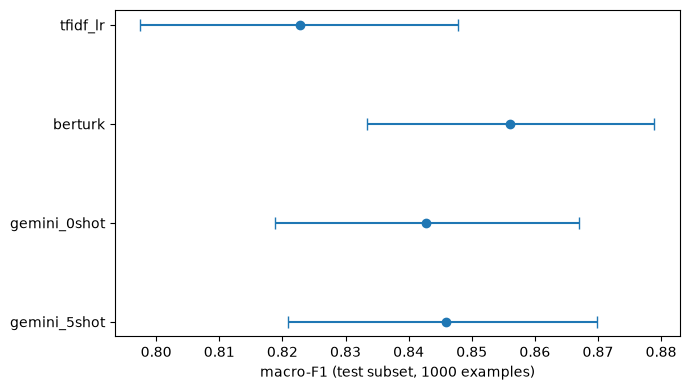

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
low_error = table_df["macro_f1"] - table_df["macro_f1_ci_low"]
high_error = table_df["macro_f1_ci_high"] - table_df["macro_f1"]
ax.errorbar(table_df["macro_f1"], table_df["model"], xerr=[low_error, high_error], fmt="o", capsize=4)
ax.set_xlabel("macro-F1 (test subset, 1000 examples)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / "plot_macro_f1_ci.png", dpi=150)
plt.show()

## Plot 2: speed and cost per model
Gemini speed is API latency (network dependent), the other two run locally on the same Mac.

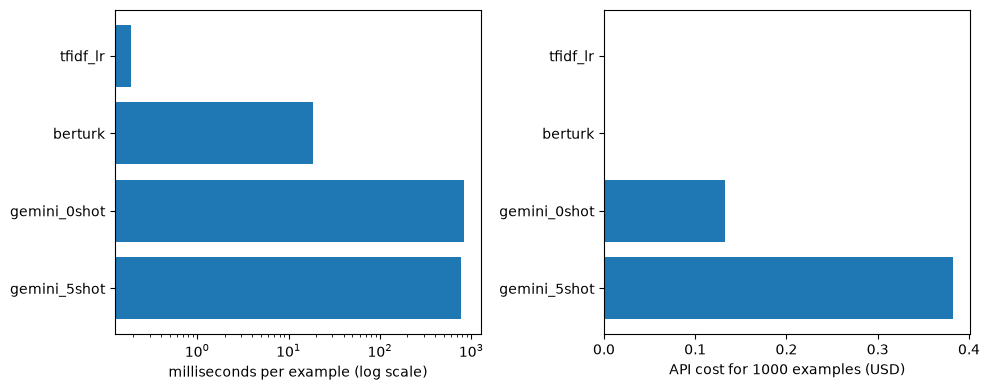

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].barh(table_df["model"], table_df["ms_per_example"])
axes[0].set_xscale("log")
axes[0].set_xlabel("milliseconds per example (log scale)")
axes[0].invert_yaxis()
axes[1].barh(table_df["model"], table_df["cost_usd"])
axes[1].set_xlabel("API cost for 1000 examples (USD)")
axes[1].invert_yaxis()
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / "plot_speed_cost.png", dpi=150)
plt.show()

## Error analysis: 100 examples sampled from the errors of 3 models
The sample is NOT random over all examples: it was drawn from three groups (35 all wrong, 40 one wrong, 25 two wrong). Category shares describe this sample, not the whole test set. Categories were set by one labeler (Claude) from the text and the true label only.

In [4]:
error_df = pd.read_csv(config.RESULTS_DIR / "error_analysis.csv")
model_columns = {"tfidf_lr": "wrong_tfidf_lr", "berturk": "wrong_berturk", "gemini_0shot": "wrong_gemini_0shot"}
category_counts = error_df["category"].value_counts()
print(category_counts)
print((category_counts / len(error_df) * 100).round(1))

category
MIX    29
NOI    19
OFF    17
REF    12
SHT     5
LNG     5
OTH     4
INF     4
NEG     4
IRO     1
Name: count, dtype: int64
category
MIX    29.0
NOI    19.0
OFF    17.0
REF    12.0
SHT     5.0
LNG     5.0
OTH     4.0
INF     4.0
NEG     4.0
IRO     1.0
Name: count, dtype: float64


## Plot 3: how many sampled errors of each category each model makes

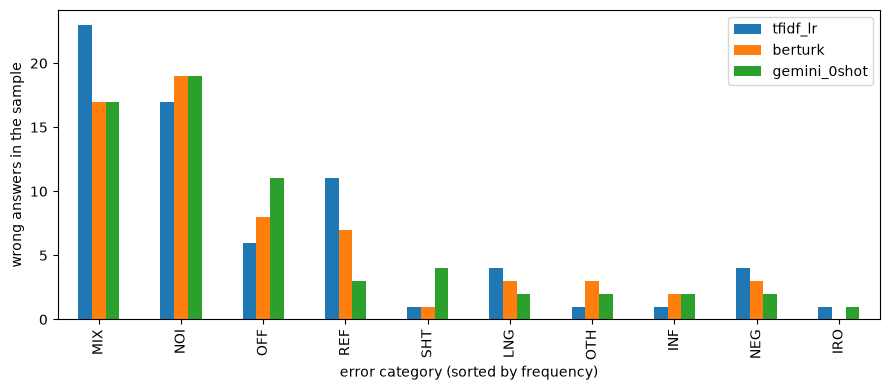

,tfidf_lr,berturk,gemini_0shot
category,,,
MIX,23,17,17
NOI,17,19,19
OFF,6,8,11
REF,11,7,3
SHT,1,1,4
LNG,4,3,2
OTH,1,3,2
INF,1,2,2
NEG,4,3,2


In [5]:
wrong_by_category = error_df.groupby("category")[list(model_columns.values())].sum()
wrong_by_category.columns = list(model_columns.keys())
wrong_by_category = wrong_by_category.loc[category_counts.index]
wrong_by_category.plot(kind="bar", figsize=(9, 4))
plt.ylabel("wrong answers in the sample")
plt.xlabel("error category (sorted by frequency)")
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / "plot_error_categories.png", dpi=150)
plt.show()
wrong_by_category

## Label noise check
Examples where the text clearly disagrees with the label (NOI as primary or secondary category).

In [6]:
noise_mask = (error_df["category"] == "NOI") | (error_df["secondary_category"] == "NOI")
print("NOI primary or secondary:", noise_mask.sum(), "of", len(error_df))
noise_df = error_df[noise_mask]
print("of these, all three models wrong:", (noise_df["n_models_wrong"] == 3).sum())
print("true label counts among NOI:", noise_df["true_label"].value_counts().to_dict())

NOI primary or secondary: 28 of 100
of these, all three models wrong: 24
true label counts among NOI: {0: 16, 1: 12}
